In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)

In [10]:
# 1. LOAD + INSPECT
# ----------------------------------------------------------
df = pd.read_csv(r"C:\Users\user\Downloads\archive (15)\heart.csv")
print(df.shape)
print(df.head())
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance (1 = heart disease):\n", df["HeartDisease"].value_counts())

(918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0

In [7]:
df=pd.get_dummies(df, drop_first=True,dtype=int)
X=df.drop(columns="HeartDisease")
y=df["HeartDisease"]
X_train, X_test, y_train, y_test=train_test_split( X,y, test_size=0.2,random_state=42,stratify=y)


In [9]:

# 3. TREE 1: NO LIMITS (grows until every leaf is pure -> overfits)
# -------------------------------------------------------------
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)
print("\n=== UNRESTRICTED TREE ===")
print("Depth         :", full_tree.get_depth())
print("Leaves     :", full_tree.get_n_leaves())
print("Train acc  :", round(full_tree.score(X_train, y_train), 4))
print("Test acc   :", round(full_tree.score(X_test, y_test), 4))


=== UNRESTRICTED TREE ===
Depth         : 14
Leaves     : 119
Train acc  : 1.0
Test acc   : 0.7826


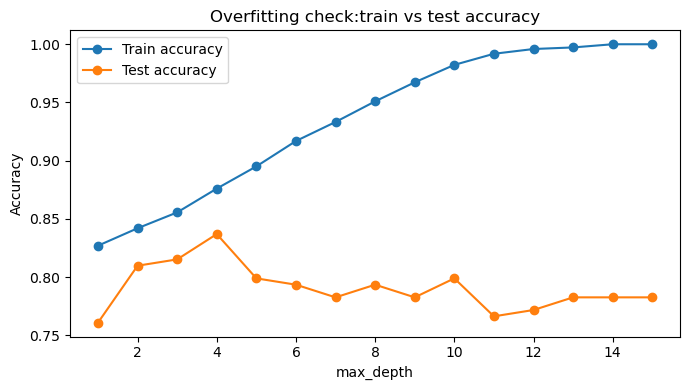

In [12]:
# 4. FIND A GOOD max_depth (train vs test accuracy curve)
# ---------------------------------------------------------
depths = range(1, 16)
train_acc, test_acc = [], []

for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting check:train vs test accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png")
plt.show()

In [13]:
# 5. TREE 2: PRUNED TREE (controlled complexity)
# ----------------------------------------------------------
tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,             # at most 3 questions deep
    min_samples_leaf=10,     # every leaf must contain at least 10 patients
    random_state=42
)
tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)


=== PRUNED TREE (max_depth=3) ===
Confusion Matrix:
 [[68 14]
 [20 82]]
TN=68  FP=14  FN=20  TP=82
Train acc : 0.8556
Test acc  : 0.8152
Precision : 0.8542
Recall    : 0.8039
F1-score  : 0.8283

               precision    recall  f1-score   support

  No disease       0.77      0.83      0.80        82
     Disease       0.85      0.80      0.83       102

    accuracy                           0.82       184
   macro avg       0.81      0.82      0.81       184
weighted avg       0.82      0.82      0.82       184



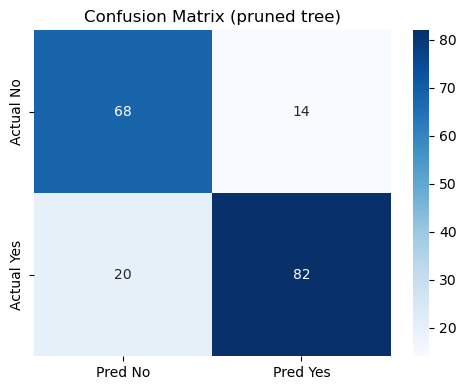

In [15]:
# 6. EVALUATE
# ----------------------------------------------------------
y_pred = tree.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("\n=== PRUNED TREE (max_depth=3) ===")
print("Confusion Matrix:\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("Train acc :", round(tree.score(X_train, y_train), 4))
print("Test acc  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues" , xticklabels=["Pred No","Pred Yes"] , yticklabels=["Actual No","Actual Yes"])
plt.title("Confusion Matrix (pruned tree)")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

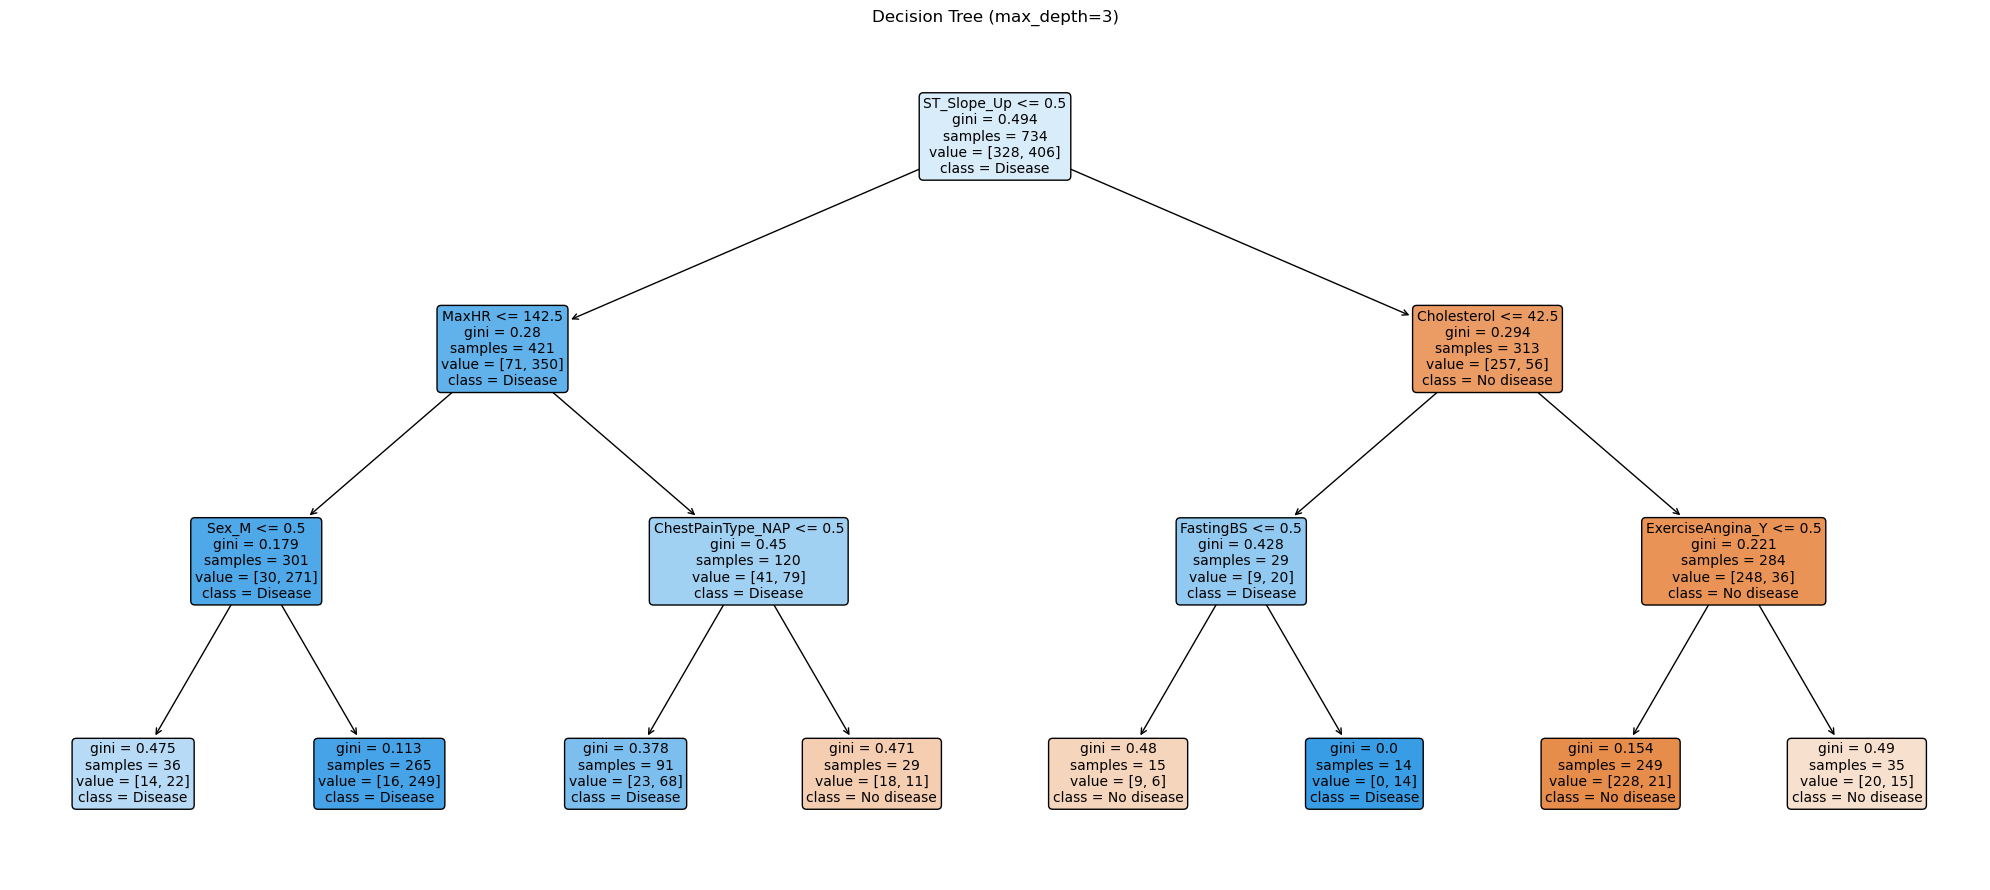

In [20]:

# 7. VISUALIZE THE TREE

plt.figure(figsize=(20, 9))

plot_tree(
    tree,
    feature_names=list(X.columns),
    class_names=["No disease", "Disease"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree (max_depth=3)")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150)
plt.show()


In [19]:
# The same tree as plain-text if/else rules
print("\nTree as text rules:\n")
print(export_text(tree, feature_names=list(X.columns)))


Tree as text rules:

|--- ST_Slope_Up <= 0.50
|   |--- MaxHR <= 142.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- class: 1
|   |--- MaxHR >  142.50
|   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |--- class: 1
|   |   |--- ChestPainType_NAP >  0.50
|   |   |   |--- class: 0
|--- ST_Slope_Up >  0.50
|   |--- Cholesterol <= 42.50
|   |   |--- FastingBS <= 0.50
|   |   |   |--- class: 0
|   |   |--- FastingBS >  0.50
|   |   |   |--- class: 1
|   |--- Cholesterol >  42.50
|   |   |--- ExerciseAngina_Y <= 0.50
|   |   |   |--- class: 0
|   |   |--- ExerciseAngina_Y >  0.50
|   |   |   |--- class: 0




Feature importances:
 ST_Slope_Up          0.746126
Cholesterol          0.081400
MaxHR                0.049056
ExerciseAngina_Y     0.035502
Sex_M                0.033395
ChestPainType_NAP    0.029068
FastingBS            0.025452
dtype: float64


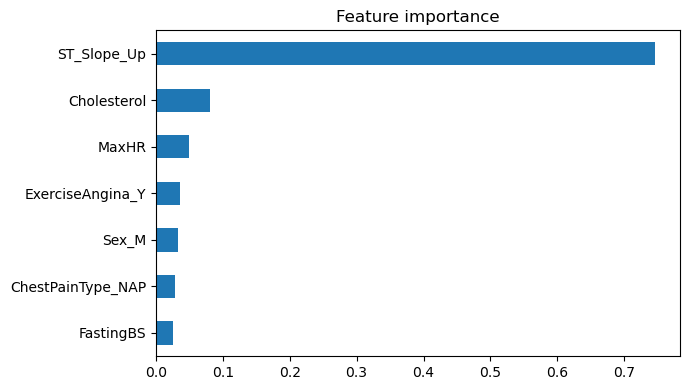

In [21]:
# 8. FEATURE IMPORTANCE
# ------------------------------------------------------------------
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature importances:\n", imp[imp > 0])

plt.figure(figsize=(7, 4))
imp[imp > 0].sort_values().plot(kind="barh")
plt.title("Feature importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()